# Project 02 — Olist E-Commerce Apriori Research

**Research question:** Can category-level association-rule mining improve cross-selling-style basket completion over popularity and item co-occurrence?

The source is a **real, anonymised Olist Brazilian marketplace dataset (2016–2018)**. This is **not** an experiment measuring incremental revenue or a next-order recommender. This notebook does not include fabricated or synthetic empirical results.


In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'olist_recs'/'data.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run the notebook inside the complete GitHub project folder')
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.olist_recs.data import load_olist, build_baskets, chronological_split
from scripts.run_research import run
RAW = ROOT/'data/raw'
OUTPUT = ROOT/'results'


## 1. Source audit and basket feasibility

Orders are joined to order items and products (plus category translation). Delivered orders with positive item prices and valid timestamps are used. A basket contains unique product categories within the same order. Product-level multi-item prevalence is audited before making any product-level claim.


In [2]:
rows = load_olist(RAW)
categories = build_baskets(rows, level='category')
products = build_baskets(rows, level='product_id')
train, validation, test = chronological_split(categories)
audit = pd.DataFrame({
    'Metric': ['Joined item rows', 'Delivered orders', 'Unique categories', 'Unique products', 'Multi-category basket share', 'Multi-product basket share', 'Train', 'Validation', 'Test'],
    'Observed': [len(rows), len(categories), rows.category.nunique(), rows.product_id.nunique(),
                 categories['items'].map(len).ge(2).mean(), products['items'].map(len).ge(2).mean(),
                 len(train), len(validation), len(test)]
})
display(audit)
display(categories['items'].map(len).value_counts().sort_index().rename('orders').to_frame().head(12))


,Metric,Observed
0,Joined item rows,108660.000000
1,Delivered orders,95146.000000
2,Unique categories,73.000000
3,Unique products,31632.000000
4,Multi-category basket share,0.007599
5,Multi-product basket share,0.033012
6,Train,57087.000000
7,Validation,19029.000000
8,Test,19030.000000


,orders
items,
1,94423
2,708
3,15


## 2. Validation-only tuning, frozen final test and paired uncertainty

The runner tunes only on the middle chronological period, refits on all pre-test data, then measures held-out masked-category Hit Rate@K. A 10,000-replicate paired bootstrap preserves invoice pairing. The output includes a fallback-aware rule trigger diagnostic.


,min_count,min_confidence,validation_hit_rate_at_10,validation_rule_trigger_rate,rule_count
0,5,0.02,0.568862,0.011976,1
1,5,0.05,0.568862,0.011976,1
2,5,0.10,0.568862,0.011976,1
3,10,0.02,0.568862,0.011976,1
4,10,0.05,0.568862,0.011976,1
5,10,0.10,0.568862,0.011976,1
6,20,0.02,0.568862,0.011976,1
7,20,0.05,0.568862,0.011976,1
8,20,0.10,0.568862,0.011976,1


,method,k,eligible_baskets,hits,hit_rate_at_k,precision_at_k,nonempty_recommendation_rate,rule_trigger_rate
0,popularity,5,181,82,0.453039,0.090608,1.0,0.00000
1,popularity,10,181,109,0.602210,0.060221,1.0,0.00000
2,cooccurrence,5,181,95,0.524862,0.104972,1.0,0.00000
3,cooccurrence,10,181,124,0.685083,0.068508,1.0,0.00000
4,apriori,5,181,82,0.453039,0.090608,1.0,0.01105
5,apriori,10,181,109,0.602210,0.060221,1.0,0.01105


Selected settings: {'min_count': 20, 'min_confidence': 0.1, 'validation_hit_rate_at_10': 0.5688622754491018, 'validation_rule_trigger_rate': 0.011976047904191617, 'rule_count': 1}
Paired interval: {'method_a': 'apriori', 'method_b': 'cooccurrence', 'k': 10, 'n': 181, 'difference': -0.08287292817679558, 'ci95_percentile': [-0.14917127071823205, -0.022099447513812154], 'replicates': 10000, 'seed': 20261115, 'interval_crosses_zero': False}


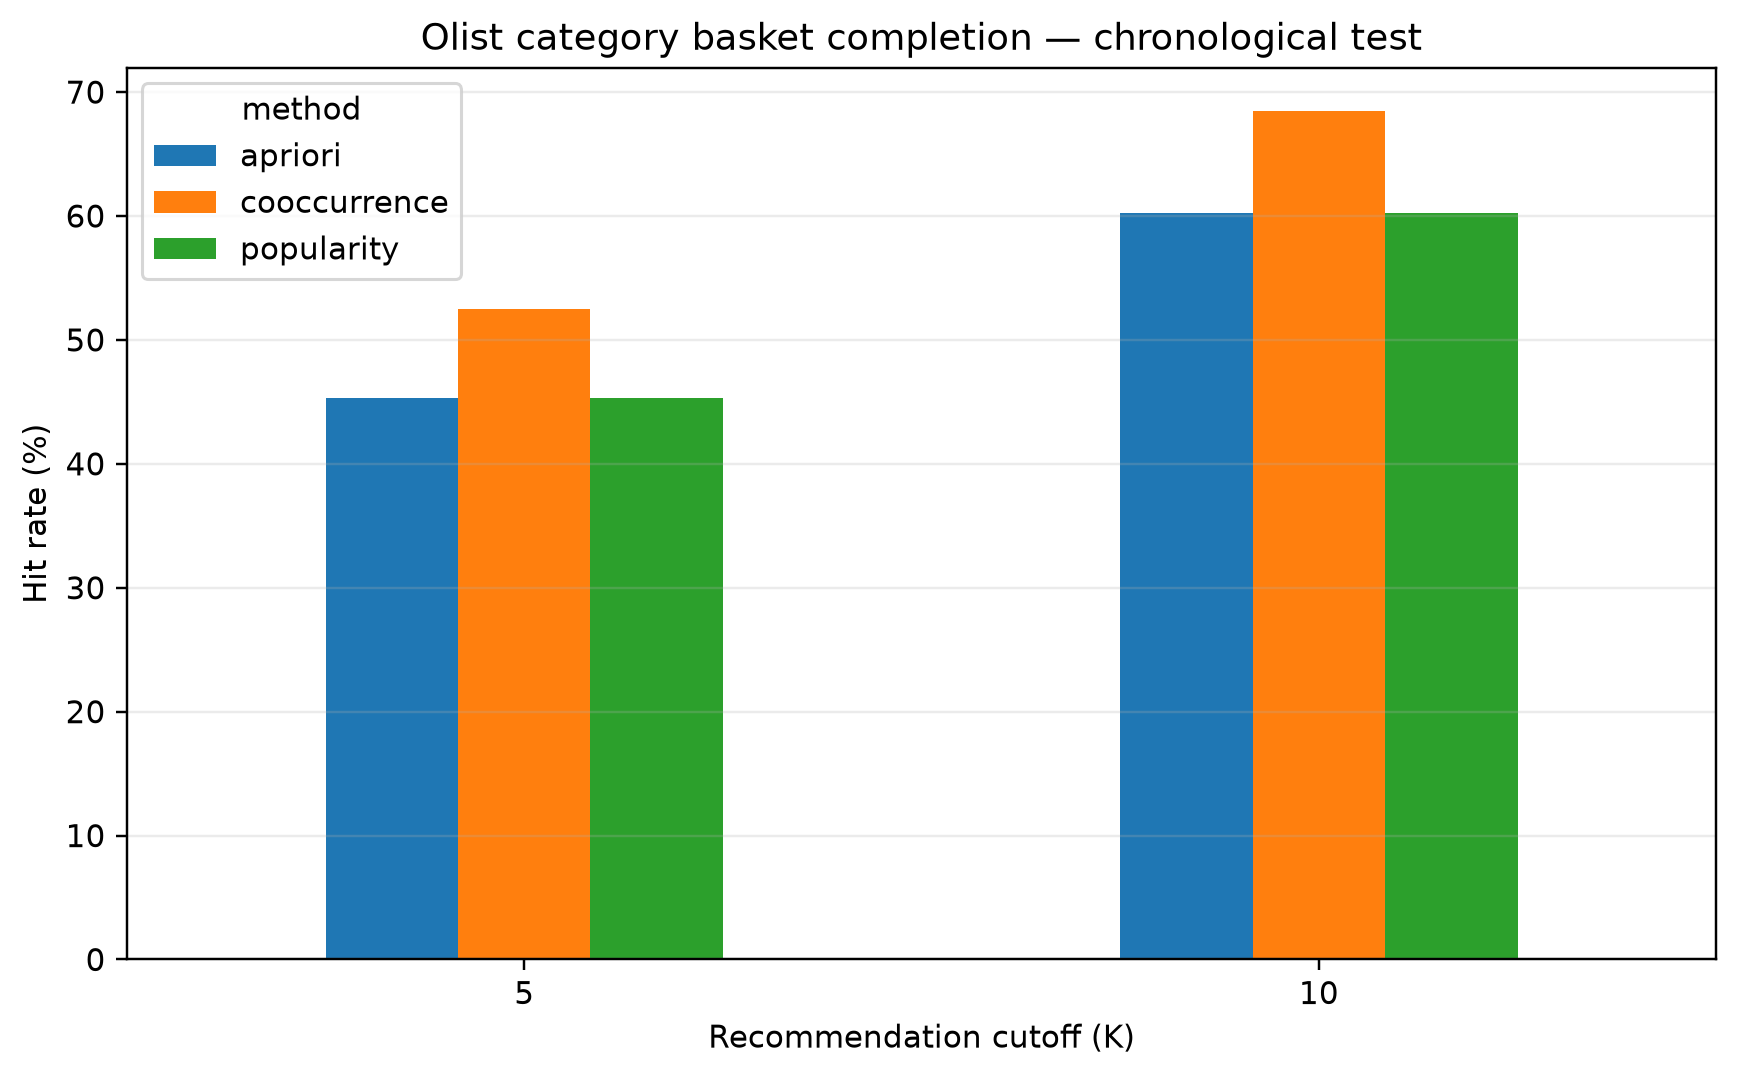

In [3]:
report = run(data_dir=RAW, output=OUTPUT, seed=42)
display(pd.DataFrame(report['validation_grid']).sort_values('validation_hit_rate_at_10',ascending=False))
display(pd.DataFrame(report['test_metrics']))
print('Selected settings:', report['selected_hyperparameters'])
print('Paired interval:', report['paired_bootstrap'])
display(Image(filename=str(OUTPUT/'figures/hit_rate.png')))


## 3. Interpretation and limitations

* Observational, historical Olist marketplace data; no measured sales uplift or causal treatment effect.
* **Masked within-order categories** are not future purchases. One hidden category makes Recall@K identical to Hit Rate@K; precision estimates depend on the chosen cutoff convention.
* Product-level co-purchasing may be too rare for stable association rules. The basket audit is essential.
* All tuning uses the validation period only; no test data enters model selection.
* Popularity fallback means the difference between a model's prediction rate and its *rule-trigger* rate matters.
* Single chronological test and one masking seed; extension: rolling-origin sensitivity and repeated mask seeds.
